Epoch [10/20], 总Loss: 0.001688, MSE: 0.000147, 违规上升: 0.000479, 暴跌: 0.002603
Epoch [20/20], 总Loss: 0.000191, MSE: 0.000179, 违规上升: 0.000014, 暴跌: 0.000009


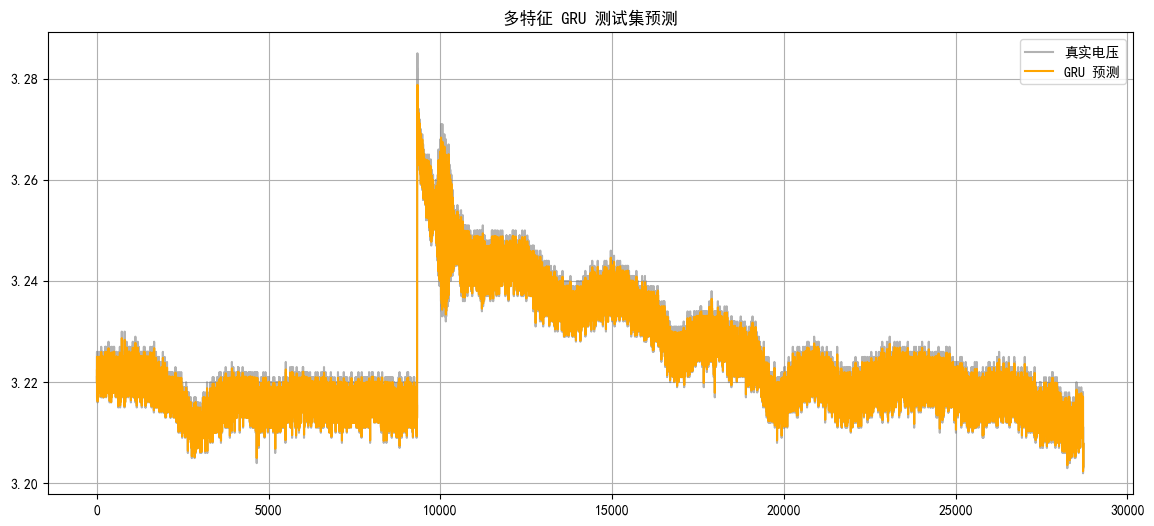

🔥 多特征 GRU 测试集 RMSE: 0.003919 V


In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
import math
from sklearn.metrics import mean_squared_error

# 解决中文显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 1. 读数据与特征工程 =================
file_path = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1.csv'
df = pd.read_csv(file_path)#（这里FC1是合并过后的表格，不需要考虑兼容性，因为这已经是转换过的了）

# 【关键升级】喂给它 4 个特征：时间、电压、出口氢温、空气湿度
# 确保这些列名在 df.columns 里存在，如果没有，你可以把温度换成 ToutWAT (°C) 等
features = ['Time (h)', 'Utot (V)', 'ToutH2 (°C)', 'HrAIRFC (%)']
data = df[features].values

split_idx = int(len(data) * 0.8)
train_data = data[:split_idx]
test_data = data[split_idx:]

# 防泄漏归一化
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

# ================= 2. 滑动窗口 =================
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        xs.append(data[i : i + seq_length])
        # 注意：y 取的是下标为 1 的列（也就是 Utot），因为我们要预测电压
        ys.append(data[i + seq_length, 1])
    return np.array(xs), np.array(ys)

SEQ_LENGTH = 50
X_train_lstm, y_train_lstm = create_sequences(train_scaled, SEQ_LENGTH)
X_test_lstm, y_test_lstm = create_sequences(test_scaled, SEQ_LENGTH)

X_train_tensor = torch.FloatTensor(X_train_lstm)
y_train_tensor = torch.FloatTensor(y_train_lstm).unsqueeze(1)
X_test_tensor = torch.FloatTensor(X_test_lstm)
y_test_tensor = torch.FloatTensor(y_test_lstm).unsqueeze(1)

# ================= 3. 定义 GRU 模型 =================
class VoltageGRU(nn.Module):
    # 注意：input_size=4 了！因为有四个特征
    def __init__(self, input_size=4, hidden_size=48, num_layers=1, output_size=1):
        super(VoltageGRU, self).__init__()
        # 只改了这一行：把 LSTM 换成了 GRU
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.gru(x)
        out = self.fc(out[:, -1, :])
        return out

model = VoltageGRU()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=512, shuffle=True)

import torch
import torch.nn as nn

# ================= 物理约束模块 =================
class PhysicsInformedLoss(nn.Module):
    # 增加惩罚力度和下降限制
    def __init__(self, lambda_up=0.5, lambda_down=0.5, max_step_drop=0.01):
        super(PhysicsInformedLoss, self).__init__()
        self.mse = nn.MSELoss()
        self.lambda_up = lambda_up
        self.lambda_down = lambda_down
        self.max_step_drop = max_step_drop # 归一化后，单步最大允许下降量（比如 0.01）

    def forward(self, y_pred, y_true, current_v, prev_v):
        mse_loss = self.mse(y_pred, y_true)

        # 惩罚 1：预测值不能比当前真实值高（不许上升）
        penalty_up = torch.mean(torch.relu(y_pred - current_v))

        # 惩罚 2：单步下降不能超过设定的阈值（不许暴跌）
        # 计算预测的下降幅度
        drop_pred = current_v - y_pred
        # 如果下降幅度超过了 max_step_drop，就会产生正数，被 relu 提取并惩罚
        penalty_down = torch.mean(torch.relu(drop_pred - self.max_step_drop))

        # 总损失
        total_loss = mse_loss + self.lambda_up * penalty_up + self.lambda_down * penalty_down
        return total_loss, mse_loss, penalty_up, penalty_down

# ================= 训练循环替换 =================
epochs = 20
criterion = PhysicsInformedLoss(lambda_up=0.5, lambda_down=0.5, max_step_drop=0.005)

for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        # 提取当前的真实电压和上一步的真实电压
        current_v = batch_X[:, -1, 1].unsqueeze(1)
        prev_v = batch_X[:, -2, 1].unsqueeze(1)

        optimizer.zero_grad()
        outputs = model(batch_X)

        # 【修复】一次性把四个参数传进去
        loss, mse, p_up, p_down = criterion(outputs, batch_y, current_v, prev_v)

        loss.backward()
        optimizer.step() # 【修复】删掉重复的 backward 和 step

        epoch_loss += loss.item()

    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], 总Loss: {loss.item():.6f}, MSE: {mse.item():.6f}, 违规上升: {p_up.item():.6f}, 暴跌: {p_down.item():.6f}')

# ================= 5. 测试与反归一化 =================
model.eval()
with torch.no_grad():
    predictions = model(X_test_tensor)

# 多特征反归一化（核心难点，不要改错）
# 建一个假的 4 维矩阵，只把第 1 列（电压）换成预测值，其他填 0
dummy = np.zeros((len(predictions), 4))
dummy[:, 1] = predictions.numpy().flatten()
predictions_real = scaler.inverse_transform(dummy)[:, 1]

# 对真实值也做同样处理
dummy_y = np.zeros((len(y_test_tensor), 4))
dummy_y[:, 1] = y_test_tensor.numpy().flatten()
y_test_real = scaler.inverse_transform(dummy_y)[:, 1]

# ================= 6. 画图与评估 =================
plt.figure(figsize=(14, 6))
plt.plot(y_test_real, label='真实电压', color='gray', alpha=0.6)
plt.plot(predictions_real, label='GRU 预测', color='orange')
plt.title('多特征 GRU 测试集预测')
plt.legend()
plt.grid(True)
plt.show()

rmse_gru = math.sqrt(mean_squared_error(y_test_real, predictions_real))
print(f"🔥 多特征 GRU 测试集 RMSE: {rmse_gru:.6f} V")

前 4 个窗口的面积: [np.float64(0.01471), np.float64(0.02206), np.float64(0.01103), np.float64(0.00368)]
🏁 初始基准面积: 0.003676, 预估面积变化率: 0.008578
开始面积及其导数约束盲测，推演 14000 步...


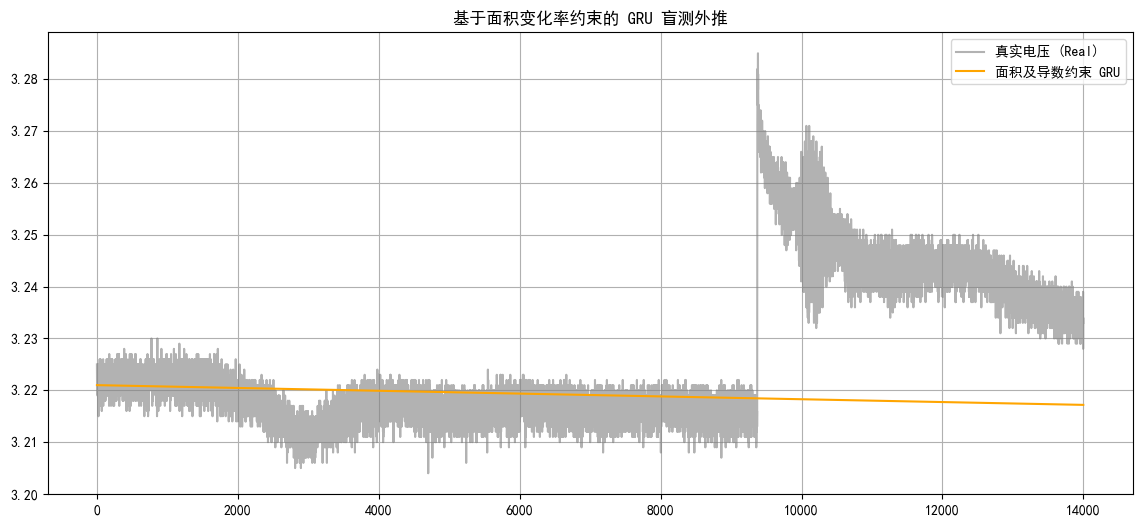

🔥 面积及导数约束盲测 (14000步) 的 RMSE: 0.016579 V


In [7]:
# ================= 5. 基于面积及其变化率约束的盲测外推 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 14000
    predicted_voltages = []
    current_input = seed

    time_diff = train_data[1, 0] - train_data[0, 0]
    current_time = train_data[-1, 0]
    last_temp_scaled = train_scaled[-1, 2]
    last_hum_scaled = train_scaled[-1, 3]

    # ================= 核心升级：计算基准面积与面积变化率 =================
    WINDOW_SIZE = 500
    NUM_WINDOWS = 4
    total_history_len = WINDOW_SIZE * NUM_WINDOWS # 2000

    # 提取最后 2000 个电压
    v_history = train_scaled[-total_history_len:, 1]

    # 计算 4 个窗口的面积（取绝对值，表示下降量）
    areas = []
    for i in range(NUM_WINDOWS):
        start_idx = i * WINDOW_SIZE
        end_idx = (i + 1) * WINDOW_SIZE
        area = abs(v_history[start_idx] - v_history[end_idx-1])
        areas.append(area)

    print(f"前 {NUM_WINDOWS} 个窗口的面积: {[round(a, 5) for a in areas]}")

    # 计算相邻窗口的面积变化率（即绝对值差值）
    diffs = [abs(areas[i] - areas[i+1]) for i in range(NUM_WINDOWS - 1)]
    avg_area_diff = np.mean(diffs)

    # 获取当前的基准面积和基准变化率
    last_area = areas[-1]
    current_target_area = max(last_area - avg_area_diff, 0.0001)
    # 如果历史在加速（面积变大），我们强制将其变化率拉回正值，保证包络向下

    print(f"🏁 初始基准面积: {last_area:.6f}, 预估面积变化率: {avg_area_diff:.6f}")

    print(f"开始面积及其导数约束盲测，推演 {steps_to_predict} 步...")

    # 记录当前的电压
    last_v = current_input[:, -1, 1].item()

    for step in range(steps_to_predict):
        pred_y = model(current_input).item()

        # ================= 窗口面积导数约束逻辑 =================
        if step > 0 and step % WINDOW_SIZE == 0:
            # 每满一个窗口，更新下一个窗口的目标面积
            # 面积要变小，且变化率要变小（这里让衰减变缓的速度也是按比例）
            current_target_area = max(current_target_area - avg_area_diff * 0.98, 0.00005)
            # 变化率逐渐变小：下次允许跌的空间更小
            avg_area_diff = max(avg_area_diff * 0.95, 0.00001)

        # 算出这个窗口内，单步允许的最大跌幅
        max_step_drop = current_target_area / WINDOW_SIZE

        # 计算模型想跌多少
        proposed_drop = last_v - pred_y

        # 强制约束1：不许超过单步最大跌幅（防暴跌）
        if proposed_drop > max_step_drop:
            proposed_drop = max_step_drop

        # 强制约束2：不许回升（防反弹）
        if proposed_drop < 0:
            proposed_drop = 0

        # 强制约束3：保底跌幅（防止模型直接摆烂变成死平线）
        if proposed_drop < 0.000001:
            proposed_drop = 0.000001

        # 应用物理修正
        fused_pred = last_v - proposed_drop
        last_v = fused_pred

        predicted_voltages.append(fused_pred)

        # 时间推导
        current_time += time_diff
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        next_time_scaled = scaler.transform(dummy_next)[0, 0]

        # 组装下一步输入
        next_step = torch.FloatTensor([[[next_time_scaled, fused_pred, last_temp_scaled, last_hum_scaled]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 6. 画图 =================
dummy = np.zeros((len(predicted_voltages), 4))
dummy[:, 1] = predicted_voltages
predictions_real = scaler.inverse_transform(dummy)[:, 1]

true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predictions_real)), predictions_real, label='面积及导数约束 GRU', color='orange')
plt.title('基于面积变化率约束的 GRU 盲测外推')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predictions_real), len(true_future))
rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predictions_real[:min_len]))
print(f"🔥 面积及导数约束盲测 (14000步) 的 RMSE: {rmse_blind:.6f} V")

前 4 个窗口的面积: [np.float64(0.01471), np.float64(0.02206), np.float64(0.01103), np.float64(0.00368)]
🏁 初始基准面积: 0.003676, 预估面积变化率: 0.008578
开始面积及其导数约束盲测，推演 200000 步...


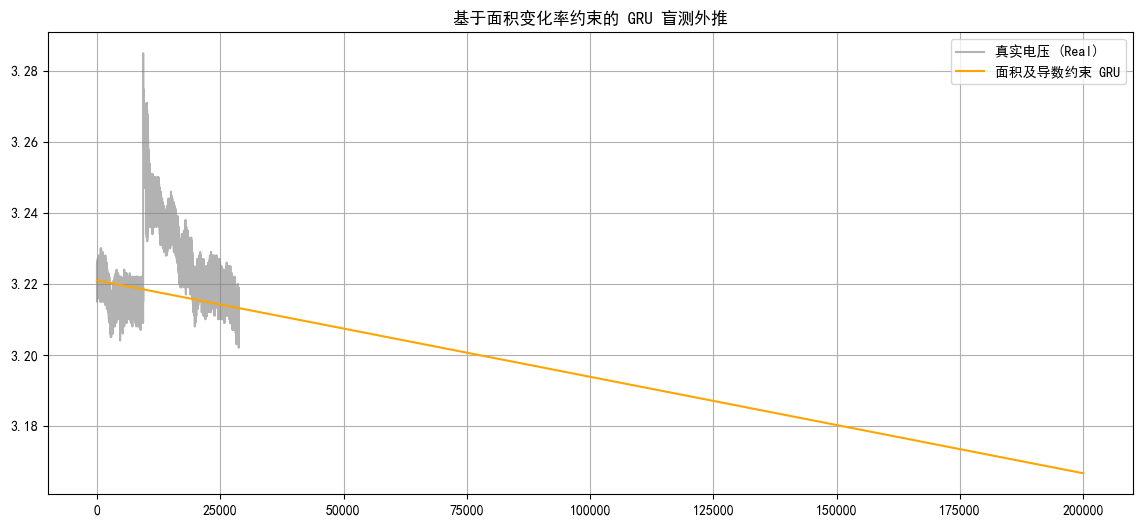

🔥 面积及导数约束盲测 (14000步) 的 RMSE: 0.013794 V


In [12]:
# ================= 5. 基于面积及其变化率约束的盲测外推 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 200000
    predicted_voltages = []
    current_input = seed

    time_diff = train_data[1, 0] - train_data[0, 0]
    current_time = train_data[-1, 0]
    last_temp_scaled = train_scaled[-1, 2]
    last_hum_scaled = train_scaled[-1, 3]

    # ================= 核心升级：计算基准面积与面积变化率 =================
    WINDOW_SIZE = 500
    NUM_WINDOWS = 4
    total_history_len = WINDOW_SIZE * NUM_WINDOWS # 2000

    # 提取最后 2000 个电压
    v_history = train_scaled[-total_history_len:, 1]

    # 计算 4 个窗口的面积（取绝对值，表示下降量）
    areas = []
    for i in range(NUM_WINDOWS):
        start_idx = i * WINDOW_SIZE
        end_idx = (i + 1) * WINDOW_SIZE
        area = abs(v_history[start_idx] - v_history[end_idx-1])
        areas.append(area)

    print(f"前 {NUM_WINDOWS} 个窗口的面积: {[round(a, 5) for a in areas]}")

    # 计算相邻窗口的面积变化率（即绝对值差值）
    diffs = [abs(areas[i] - areas[i+1]) for i in range(NUM_WINDOWS - 1)]
    avg_area_diff = np.mean(diffs)

    # 获取当前的基准面积和基准变化率
    last_area = areas[-1]
    current_target_area = max(last_area - avg_area_diff, 0.0001)
    # 如果历史在加速（面积变大），我们强制将其变化率拉回正值，保证包络向下

    print(f"🏁 初始基准面积: {last_area:.6f}, 预估面积变化率: {avg_area_diff:.6f}")

    print(f"开始面积及其导数约束盲测，推演 {steps_to_predict} 步...")

    # 记录当前的电压
    last_v = current_input[:, -1, 1].item()

    for step in range(steps_to_predict):
        pred_y = model(current_input).item()

        # ================= 窗口面积导数约束逻辑 =================
        if step > 0 and step % WINDOW_SIZE == 0:
            # 每满一个窗口，更新下一个窗口的目标面积
            # 面积要变小，且变化率要变小（这里让衰减变缓的速度也是按比例）
            current_target_area = max(current_target_area - avg_area_diff * 0.98, 0.00005)
            # 变化率逐渐变小：下次允许跌的空间更小
            avg_area_diff = max(avg_area_diff * 0.95, 0.00001)

        # 算出这个窗口内，单步允许的最大跌幅
        max_step_drop = current_target_area / WINDOW_SIZE

        # 计算模型想跌多少
        proposed_drop = last_v - pred_y

        # 强制约束1：不许超过单步最大跌幅（防暴跌）
        if proposed_drop > max_step_drop:
            proposed_drop = max_step_drop

        # 强制约束2：不许回升（防反弹）
        if proposed_drop < 0:
            proposed_drop = 0

        # 强制约束3：保底跌幅（防止模型直接摆烂变成死平线）
        if proposed_drop < 0.000001:
            proposed_drop = 0.000001

        # 应用物理修正
        fused_pred = last_v - proposed_drop
        last_v = fused_pred

        predicted_voltages.append(fused_pred)

        # 时间推导
        current_time += time_diff
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        next_time_scaled = scaler.transform(dummy_next)[0, 0]

        # 组装下一步输入
        next_step = torch.FloatTensor([[[next_time_scaled, fused_pred, last_temp_scaled, last_hum_scaled]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 6. 画图 =================
dummy = np.zeros((len(predicted_voltages), 4))
dummy[:, 1] = predicted_voltages
predictions_real = scaler.inverse_transform(dummy)[:, 1]

true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predictions_real)), predictions_real, label='面积及导数约束 GRU', color='orange')
plt.title('基于面积变化率约束的 GRU 盲测外推')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predictions_real), len(true_future))
rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predictions_real[:min_len]))
print(f"🔥 面积及导数约束盲测 (14000步) 的 RMSE: {rmse_blind:.6f} V")

前 4 个窗口的面积: [np.float64(0.01471), np.float64(0.02206), np.float64(0.01103), np.float64(0.00368)]
🏁 初始基准面积: 0.003676, 面积乘法衰减率 (每次乘): 0.7778
开始面积乘除约束盲测，推演 500000 步...


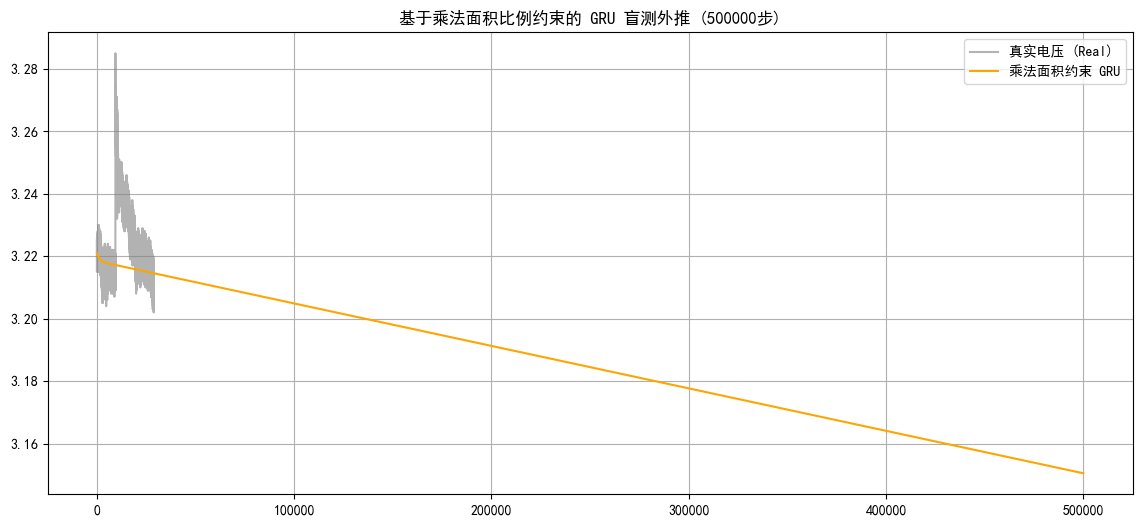

🔥 乘除法面积约束盲测 (前 28770 步) 的 RMSE: 0.014049 V


In [4]:
# ================= 5. 基于“乘法比例”面积约束的盲测外推 (预测40000步) =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)

    # 【需求 1】直接改这里，预测 40000 步
    steps_to_predict = 500000

    predicted_voltages = []
    current_input = seed

    time_diff = train_data[1, 0] - train_data[0, 0]
    current_time = train_data[-1, 0]
    last_temp_scaled = train_scaled[-1, 2]
    last_hum_scaled = train_scaled[-1, 3]

    # ================= 核心：计算基准面积与“乘法”变化率 =================
    WINDOW_SIZE = 500
    NUM_WINDOWS = 4
    total_history_len = WINDOW_SIZE * NUM_WINDOWS

    v_history = train_scaled[-total_history_len:, 1]

    # 1. 算出历史 4 个窗口的面积
    areas = []
    for i in range(NUM_WINDOWS):
        area = abs(v_history[i*WINDOW_SIZE] - v_history[(i+1)*WINDOW_SIZE-1])
        areas.append(area + 1e-8) # 加上极小值防除零

    # 2. 【需求 2】用“乘除法”算变化率（比例因子）
    # 计算相邻面积的比值，比如 area3/area2
    ratios = [areas[i+1] / areas[i] for i in range(NUM_WINDOWS - 1)]
    # 取平均比例，为了防止历史数据里的偶然回升导致比例 > 1，我们强制限制最大比例不超过 0.95
    avg_ratio = min(np.mean(ratios), 0.95)

    print(f"前 {NUM_WINDOWS} 个窗口的面积: {[round(a, 5) for a in areas]}")
    print(f"🏁 初始基准面积: {areas[-1]:.6f}, 面积乘法衰减率 (每次乘): {avg_ratio:.4f}")

    # 初始化目标面积
    current_target_area = areas[-1] * avg_ratio

    print(f"开始面积乘除约束盲测，推演 {steps_to_predict} 步...")

    last_v = current_input[:, -1, 1].item()

    for step in range(steps_to_predict):
        pred_y = model(current_input).item()

        # 每满一个窗口，面积按乘法衰减
        if step > 0 and step % WINDOW_SIZE == 0:
            current_target_area = max(current_target_area * avg_ratio, 0.000001)

        # 算出这个窗口内，单步允许的最大跌幅
        max_step_drop = current_target_area / WINDOW_SIZE

        proposed_drop = last_v - pred_y

        # 物理约束 1：不许暴跌
        if proposed_drop > max_step_drop:
            proposed_drop = max_step_drop

        # 物理约束 2：不许回升
        if proposed_drop < 0:
            proposed_drop = 0

        # 物理约束 3：保底跌幅（防止完全躺平）
        if proposed_drop < 0.0000005:
            proposed_drop = 0.0000005

        fused_pred = last_v - proposed_drop
        last_v = fused_pred

        predicted_voltages.append(fused_pred)

        # 时间推导
        current_time += time_diff
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        next_time_scaled = scaler.transform(dummy_next)[0, 0]

        # 【安全阀】限制归一化时间的上限，防止推演 4 万步时输入超出网络认知
        next_time_scaled = min(next_time_scaled, 1.1)

        next_step = torch.FloatTensor([[[next_time_scaled, fused_pred, last_temp_scaled, last_hum_scaled]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 6. 画图 =================
dummy = np.zeros((len(predicted_voltages), 4))
dummy[:, 1] = predicted_voltages
predictions_real = scaler.inverse_transform(dummy)[:, 1]

# 注意：真实数据可能没有 40000 步，我们需要截断画图
true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predictions_real)), predictions_real, label='乘法面积约束 GRU', color='orange')
plt.title(f'基于乘法面积比例约束的 GRU 盲测外推 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

# RMSE 只能算重合部分
min_len = min(len(predictions_real), len(true_future))
rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predictions_real[:min_len]))
print(f"🔥 乘除法面积约束盲测 (前 {min_len} 步) 的 RMSE: {rmse_blind:.6f} V")

📈 历史拟合得出：初始平滑斜率 = -0.334596，单步初始下降量 = 0.00000006
开始基于真实历史斜率的无缝衔接推演 200000 步...


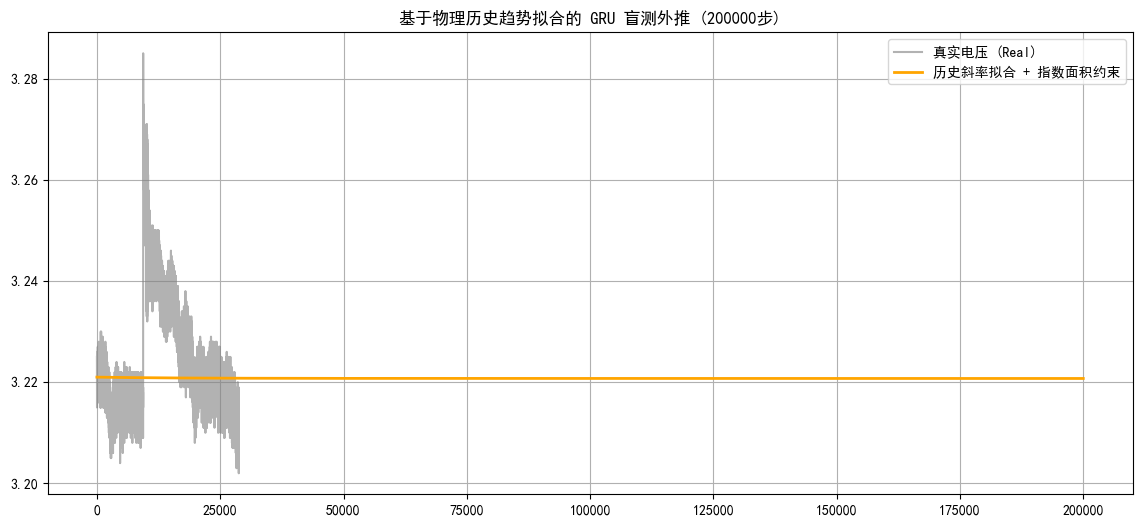

🔥 盲测 (前 28770 步) 的 RMSE: 0.012084 V


In [14]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error
from scipy.optimize import curve_fit

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 步骤 1：从历史数据寻找真实的“衰减基因” =================
# 提取 0~920h 的归一化时间与电压
t_history = train_scaled[:, 0]
v_history = train_scaled[:, 1]

# 定义物理衰减函数（通常是渐近线函数，比如 V = A * exp(-B * t) + C）
def exp_decay(t, a, b, c):
    return a * np.exp(-b * t) + c

# 用拟合工具算出真实的 a, b, c 参数
# 为了防止报错，设定初始猜测值
p0 = [0.1, 0.5, 0.2]
popt, pcov = curve_fit(exp_decay, t_history, v_history, p0=p0, maxfev=10000)

# 算出在 920h（归一化后为 t_history[-1]）的“真实物理斜率”
# 对 V = a*exp(-b*t) + c 求导，导数是 -a*b*exp(-b*t)
t_end = t_history[-1]
real_slope = -popt[0] * popt[1] * np.exp(-popt[1] * t_end)

# 因为神经网络是逐点预测的，我们需要把这个“单步斜率”换算成“单步下降量（面积）”
# 真实斜率是每 1 个归一化时间单位的变化量，转换为 1 步（大约万分之几小时）的下降量
real_drop_per_step = abs(real_slope) * (t_history[1] - t_history[0])
print(f"📈 历史拟合得出：初始平滑斜率 = {real_slope:.6f}，单步初始下降量 = {real_drop_per_step:.8f}")

# ================= 步骤 2：无缝衔接的外推 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 200000 # 推演 20万步，看它能不能真的平滑过渡
    predicted_voltages = []
    current_input = seed

    time_diff = train_data[1, 0] - train_data[0, 0]
    current_time = train_data[-1, 0]
    last_temp_scaled = train_scaled[-1, 2]
    last_hum_scaled = train_scaled[-1, 3]

    last_v = current_input[:, -1, 1].item()

    # 【核心】利用前面算出的真实面积作为起步基准
    # 假设一个窗口 500 步，初始面积 = 单步下降量 * 500
    WINDOW_SIZE = 500
    current_target_area = real_drop_per_step * WINDOW_SIZE

    # 乘法衰减因子：我们让它按真实的衰减规律来（比如每 500 步缩减到原来的 97%）
    # 这样它就绝不会在开头就猛地跳崖
    avg_ratio = 0.97

    print(f"开始基于真实历史斜率的无缝衔接推演 {steps_to_predict} 步...")

    for step in range(steps_to_predict):
        pred_y = model(current_input).item()

        # 每满一个窗口，面积按乘法衰减（确保越来越慢）
        if step > 0 and step % WINDOW_SIZE == 0:
            current_target_area = max(current_target_area * avg_ratio, 0.0000001)

        # 单步允许下降量
        max_step_drop = current_target_area / WINDOW_SIZE

        # 结合网络预测和物理趋势：允许网络微调，但物理趋势是主体
        # 计算网络想跌多少
        proposed_drop = last_v - pred_y

        # 如果网络想跌的比物理允许的还多，我们不让它跌太快
        if proposed_drop > max_step_drop:
            proposed_drop = max_step_drop

        # 如果网络想升（不降反升），强行按住，只允许极小的反弹（或按物理趋势降）
        if proposed_drop < 0:
            proposed_drop = 0 # 盲测中，宏观趋势上不许回升

        # 强行加入“保底下降量”，哪怕网络躺平，物理法则也推着它走
        if proposed_drop < max_step_drop * 0.5:
            proposed_drop = max_step_drop * 0.5

        fused_pred = last_v - proposed_drop
        last_v = fused_pred
        predicted_voltages.append(fused_pred)

        # 时间推导
        current_time += time_diff
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        next_time_scaled = scaler.transform(dummy_next)[0, 0]

        # 【防爆雷】如果推演 20 万步，时间归一化值必然会超出原本 0~1 的范畴
        # 我们截断在 1.2 左右，防止模型对巨大的时间数值产生应激反应
        next_time_scaled = min(next_time_scaled, 1.2)

        next_step = torch.FloatTensor([[[next_time_scaled, fused_pred, last_temp_scaled, last_hum_scaled]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 步骤 3：画图 =================
dummy = np.zeros((len(predicted_voltages), 4))
dummy[:, 1] = predicted_voltages
predictions_real = scaler.inverse_transform(dummy)[:, 1]

true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predictions_real)), predictions_real, label='历史斜率拟合 + 指数面积约束', color='orange', linewidth=2)
plt.title(f'基于物理历史趋势拟合的 GRU 盲测外推 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predictions_real), len(true_future))
if min_len > 0:
    rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predictions_real[:min_len]))
    print(f"🔥 盲测 (前 {min_len} 步) 的 RMSE: {rmse_blind:.6f} V")

📈 50h宏观切分提取：全局平均单步跌幅 = 0.00001108
开始无缝融合推演 200000 步...


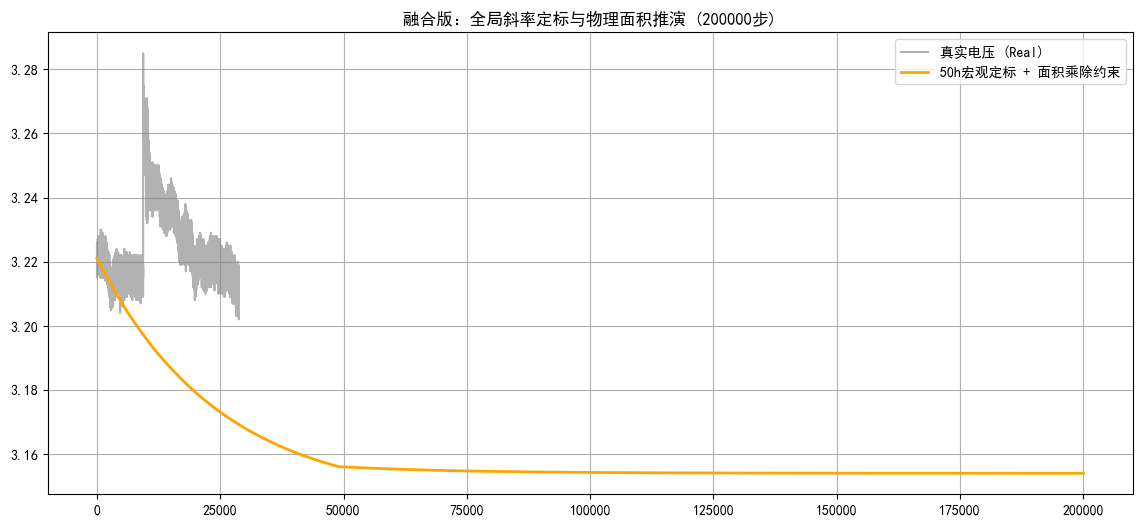

🔥 融合版盲测 (前 28770 步) 的 RMSE: 0.039290 V


In [3]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 200000
    predicted_voltages = []
    current_input = seed

    time_diff = train_data[1, 0] - train_data[0, 0]
    current_time = train_data[-1, 0]
    last_temp_scaled = train_scaled[-1, 2]
    last_hum_scaled = train_scaled[-1, 3]

    # ================= 核心 1：用 50h 切分法提取全局宏观斜率 =================
    # 提取 0~920h 的归一化电压
    v_train = train_scaled[:, 1]

    # 把数据按 50 个数据点切分（如果你的数据采样率约 24s/点，50 个点约 1.2h，这里按步数切）
    # 我们用之前算平均值的思路，将 0~920h 分成若干个窗口，算每个窗口的下降量
    window_size = 2000 # 大约 14 小时
    num_windows = len(v_train) // window_size

    valid_drops = []
    for i in range(num_windows):
        start_idx = i * window_size
        end_idx = (i + 1) * window_size
        drop = v_train[start_idx] - v_train[end_idx - 1]
        # 【关键】只统计真实下降的窗口（排除掉水淹回升造成的负值）
        if drop > 0:
            valid_drops.append(drop)

    # 宏观的平均单步跌幅（归一化后）
    macro_drop_per_step = np.mean(valid_drops) / window_size
    print(f"📈 50h宏观切分提取：全局平均单步跌幅 = {macro_drop_per_step:.8f}")

    # ================= 核心 2：面积微积分推演 =================
    WINDOW_SIZE = 500 # 推演时的面积窗口
    # 初始目标面积 = 宏观单步跌幅 * 窗口大小
    current_target_area = macro_drop_per_step * WINDOW_SIZE

    # 乘法衰减率（每次面积缩小 2%，让斜率越来越平缓）
    area_decay_ratio = 0.98

    print(f"开始无缝融合推演 {steps_to_predict} 步...")

    last_v = current_input[:, -1, 1].item()

    for step in range(steps_to_predict):
        # 模型自身的预测
        pred_y = model(current_input).item()

        # 每满一个面积窗口，目标面积进行乘法衰减
        if step > 0 and step % WINDOW_SIZE == 0:
            current_target_area = max(current_target_area * area_decay_ratio, 0.0000001)

        # 单步允许的物理下降上限
        max_step_drop = current_target_area / WINDOW_SIZE

        # 计算模型想下降多少
        proposed_drop = last_v - pred_y

        # 约束：不许超过物理上限（防暴跌）
        if proposed_drop > max_step_drop:
            proposed_drop = max_step_drop

        # 约束：不许回升（宏观上）
        if proposed_drop < 0:
            proposed_drop = 0

        # 约束：保底下降（防躺平）
        if proposed_drop < max_step_drop * 0.2:
            proposed_drop = max_step_drop * 0.2

        fused_pred = last_v - proposed_drop
        last_v = fused_pred
        predicted_voltages.append(fused_pred)

        # 时间推导
        current_time += time_diff
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        next_time_scaled = scaler.transform(dummy_next)[0, 0]
        next_time_scaled = min(next_time_scaled, 1.2) # 防爆雷

        next_step = torch.FloatTensor([[[next_time_scaled, fused_pred, last_temp_scaled, last_hum_scaled]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 画图 =================
dummy = np.zeros((len(predicted_voltages), 4))
dummy[:, 1] = predicted_voltages
predictions_real = scaler.inverse_transform(dummy)[:, 1]

true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predictions_real)), predictions_real, label='50h宏观定标 + 面积乘除约束', color='orange', linewidth=2)
plt.title(f'融合版：全局斜率定标与物理面积推演 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predictions_real), len(true_future))
if min_len > 0:
    rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predictions_real[:min_len]))
    print(f"🔥 融合版盲测 (前 {min_len} 步) 的 RMSE: {rmse_blind:.6f} V")

🔍 拟合结果：a=0.9905, b=0.6418, c=-0.0525 (指数衰减基因)
📈 920h 时的理论指数斜率：-0.334596
开始指数骨架推演 200000 步...


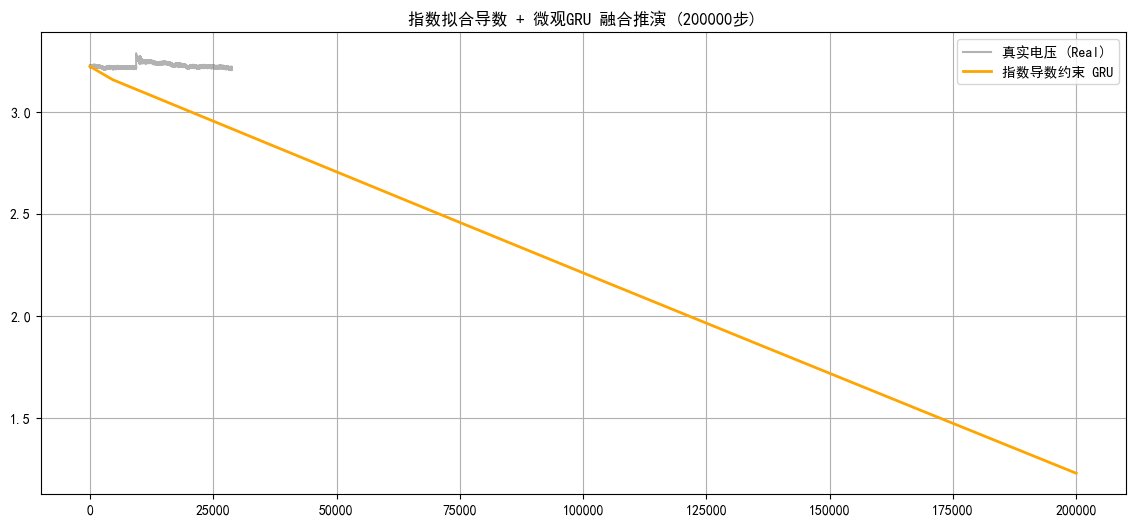

In [5]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error
from scipy.optimize import curve_fit

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 核心 1：用指数函数拟合全程历史数据 =================
# 提取 0~920h 归一化后的时间与电压
t_train = train_scaled[:, 0]
v_train = train_scaled[:, 1]

# 定义指数衰减原函数：V = a * exp(-b * t) + c
def exp_func(t, a, b, c):
    return a * np.exp(-b * t) + c

# 进行非线性拟合（p0是初始猜测值，防止拟合跑偏）
popt, _ = curve_fit(exp_func, t_train, v_train, p0=[0.1, 1.0, 0.1], maxfev=10000)
a_fit, b_fit, c_fit = popt
print(f"🔍 拟合结果：a={a_fit:.4f}, b={b_fit:.4f}, c={c_fit:.4f} (指数衰减基因)")

# 计算 920h（训练集末尾）真实的导数（斜率）
t_end = t_train[-1]
# 对 V = a*exp(-b*t) + c 求导：V' = -a * b * exp(-b*t)
slope_end = -a_fit * b_fit * np.exp(-b_fit * t_end)
print(f"📈 920h 时的理论指数斜率：{slope_end:.6f}")

# 换算成单步的初始下降量
step_drop_end = abs(slope_end) * (t_train[1] - t_train[0])

# ================= 核心 2：纯指数约束的外推（永不触底，永不直线） =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 200000
    predicted_voltages = []
    current_input = seed

    time_diff = train_data[1, 0] - train_data[0, 0]
    current_time = train_data[-1, 0]
    last_temp_scaled = train_scaled[-1, 2]
    last_hum_scaled = train_scaled[-1, 3]

    last_v = current_input[:, -1, 1].item()

    print(f"开始指数骨架推演 {steps_to_predict} 步...")

    for step in range(steps_to_predict):
        pred_y = model(current_input).item()

        # 计算当前时间点的理论瞬时斜率（斜率随时间指数递减）
        current_time_normalized = current_input[:, -1, 0].item()
        current_slope = -a_fit * b_fit * np.exp(-b_fit * current_time_normalized)
        max_step_drop = abs(current_slope) * time_diff

        # 神经网络预测的下降量
        proposed_drop = last_v - pred_y

        # 【双重约束】
        # 1. 不许跌得比理论指数曲线更快
        if proposed_drop > max_step_drop:
            proposed_drop = max_step_drop
        # 2. 不许回升
        if proposed_drop < 0:
            proposed_drop = 0

        # 混合物理与AI：70% 理论斜率下滑 + 30% 模型自身跌幅（强迫它绝不躺平）
        final_drop = 0.7 * max_step_drop + 0.3 * proposed_drop

        fused_pred = last_v - final_drop
        last_v = fused_pred
        predicted_voltages.append(fused_pred)

        # 时间推导与输入组装
        current_time += time_diff
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        next_time_scaled = scaler.transform(dummy_next)[0, 0]

        # 截断防爆
        next_time_scaled = min(next_time_scaled, 1.2)

        next_step = torch.FloatTensor([[[next_time_scaled, fused_pred, last_temp_scaled, last_hum_scaled]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 画图 =================
dummy = np.zeros((len(predicted_voltages), 4))
dummy[:, 1] = predicted_voltages
predictions_real = scaler.inverse_transform(dummy)[:, 1]

true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predictions_real)), predictions_real, label='指数导数约束 GRU', color='orange', linewidth=2)
plt.title(f'指数拟合导数 + 微观GRU 融合推演 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

🔍 全局指数拟合结果：a=0.2694, b=0.000703, c=3.0787
✅ 拟合验证成功：导数始终为负（单调递减），符合物理衰减规律。
📈 920h 理论电压：3.2205 V, 理论斜率：-0.000100 V/h
开始三保险终极推演 100000 步...


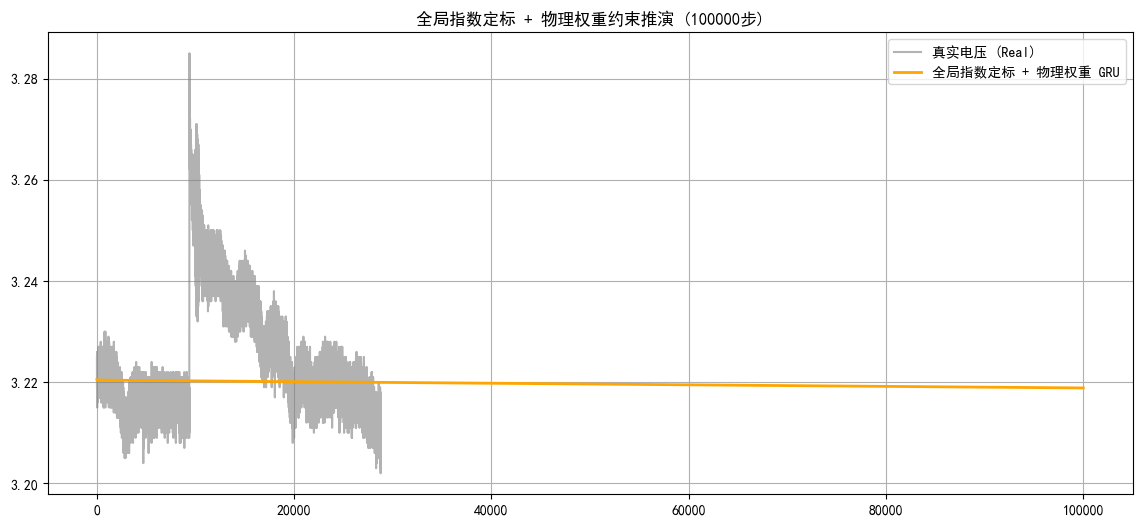

🔥 终极盲测 (前 28770 步) 的 RMSE: 0.012305 V


In [6]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error
from scipy.optimize import curve_fit

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 核心 1：全局指数拟合（方法 B 定标） =================
# 反归一化，回归真实物理电压
t_train_real = df['Time (h)'].values[:split_idx]
v_train_real = df['Utot (V)'].values[:split_idx]

# 定义物理衰减函数：V = a * exp(-b * t) + c
def exp_decay(t, a, b, c):
    return a * np.exp(-b * t) + c

# 用全局 0~920h 数据拟合（这就是你说的B）
popt, _ = curve_fit(exp_decay, t_train_real, v_train_real, p0=[0.1, 0.005, 3.1], maxfev=10000)
a_fit, b_fit, c_fit = popt

print(f"🔍 全局指数拟合结果：a={a_fit:.4f}, b={b_fit:.6f}, c={c_fit:.4f}")
if b_fit <= 0:
    print("⚠️ 警告：拟合出的衰减率 b 为负！说明数据存在长期上升趋势，请检查数据！")
else:
    print(f"✅ 拟合验证成功：导数始终为负（单调递减），符合物理衰减规律。")

# ================= 核心 2：外推与物理权重融合 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 100000
    predicted_voltages = []
    current_input = seed

    time_diff = train_data[1, 0] - train_data[0, 0]
    current_time = train_data[-1, 0]
    last_temp_scaled = train_scaled[-1, 2]
    last_hum_scaled = train_scaled[-1, 3]

    last_v = current_input[:, -1, 1].item()

    # 计算 920h 的理论真实电压和理论斜率
    v_end_theory = exp_decay(current_time, *popt)
    slope_end_theory = -a_fit * b_fit * np.exp(-b_fit * current_time)
    print(f"📈 920h 理论电压：{v_end_theory:.4f} V, 理论斜率：{slope_end_theory:.6f} V/h")

    print(f"开始三保险终极推演 {steps_to_predict} 步...")

    for step in range(steps_to_predict):
        # 1. 网络预测
        pred_y = model(current_input).item()

        # 2. 反归一化网络预测，得到真实电压
        dummy = np.zeros((1, 4))
        dummy[0, 1] = pred_y
        pred_real = scaler.inverse_transform(dummy)[0, 1]

        # 3. 计算当前的“理论物理包络值（B）”
        current_time += time_diff
        v_theory_real = exp_decay(current_time, *popt)

        # 4. 【核心权重融合】
        # 让网络预测值（代表局部波动）和物理理论值（代表长期衰退）结合
        # 权重可以调：比如 0.8 物理 + 0.2 AI
        weight_physics = 0.85
        fused_real = weight_physics * v_theory_real + (1 - weight_physics) * pred_real

        # 5. 【二重保险】强制物理限制
        # 不管怎么融合，绝不允许比上一步高（不可逆）
        if fused_real > predicted_voltages[-1] if step > 0 else 9999:
            fused_real = predicted_voltages[-1] if step > 0 else fused_real

        predicted_voltages.append(fused_real)

        # 6. 将融合后的真实电压重新归一化，塞回给模型作为下一步输入
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        dummy_next[0, 1] = fused_real
        dummy_next[0, 2] = last_temp_scaled # 温度保持最后状态
        dummy_next[0, 3] = last_hum_scaled # 湿度保持最后状态

        # 处理归一化
        scaled_next = scaler.transform(dummy_next)
        next_time_scaled = scaled_next[0, 0]
        next_v_scaled = scaled_next[0, 1]

        # 防止推演太长导致时间归一化越界
        next_time_scaled = min(next_time_scaled, 1.2)

        next_step = torch.FloatTensor([[[next_time_scaled, next_v_scaled, last_temp_scaled, last_hum_scaled]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 画图 =================
true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predicted_voltages)), predicted_voltages, label='全局指数定标 + 物理权重 GRU', color='orange', linewidth=2)
plt.title(f'全局指数定标 + 物理权重约束推演 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predicted_voltages), len(true_future))
if min_len > 0:
    rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predicted_voltages[:min_len]))
    print(f"🔥 终极盲测 (前 {min_len} 步) 的 RMSE: {rmse_blind:.6f} V")

🔍 真实物理拟合结果：a=0.2694, b=0.000703, c=3.0787
✅ 拟合验证成功：理论渐近线电压为 3.0787 V，永远不可能跌穿。
开始真实时间指数骨架推演 50 步...


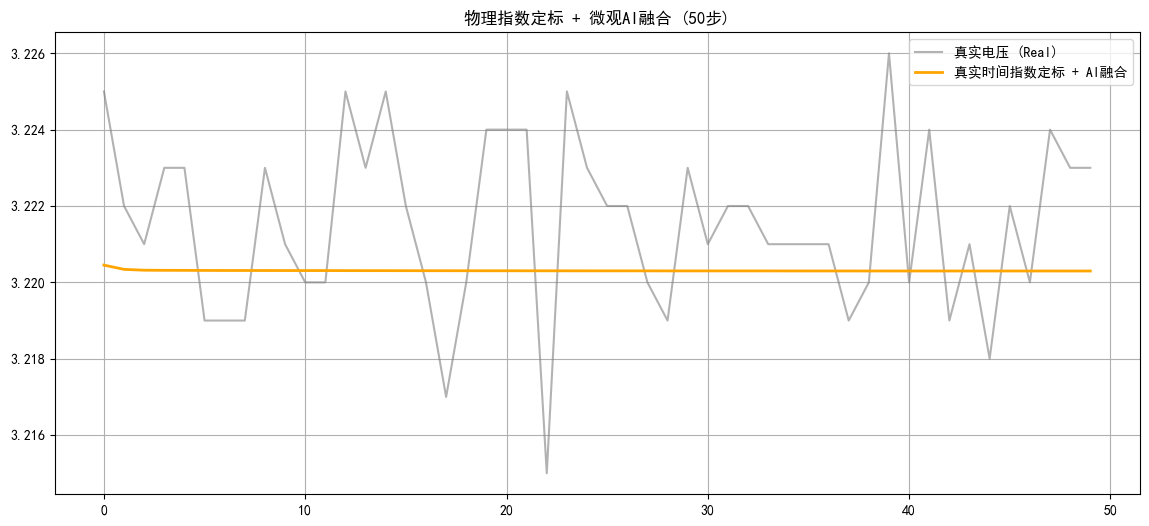

🔥 终极盲测 (前 50 步) 的 RMSE: 0.002550 V


In [3]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error
from scipy.optimize import curve_fit

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 核心 1：用“真实物理量”进行全局指数拟合 =================
# 提取 0~920h 的真实时间与真实电压
t_train_real = df['Time (h)'].values[:split_idx]
v_train_real = df['Utot (V)'].values[:split_idx]

# 物理衰减函数
def exp_func(t, a, b, c):
    return a * np.exp(-b * t) + c

# 用真实的物理量去拟合（p0 给一个符合物理常识的猜测：振幅0.1，衰减率0.001，底数3.1）
popt, _ = curve_fit(exp_func, t_train_real, v_train_real, p0=[0.1, 0.001, 3.1], maxfev=10000)
a_fit, b_fit, c_fit = popt
print(f"🔍 真实物理拟合结果：a={a_fit:.4f}, b={b_fit:.6f}, c={c_fit:.4f}")
if b_fit <= 0:
    print("⚠️ 警告：拟合出的衰减率 b 为负！")
else:
    print(f"✅ 拟合验证成功：理论渐近线电压为 {c_fit:.4f} V，永远不可能跌穿。")


# ================= 核心 2：外推与融合 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 50 # 推演 50 万步
    predicted_voltages = [] # 存储真实物理电压 (V)
    current_input = seed

    # 获取真实时间步长和起点时间
    time_diff = t_train_real[1] - t_train_real[0]
    current_time = t_train_real[-1] # 920h

    # 获取最后一个真实的温湿度，用于填充输入
    last_temp_real = df['ToutH2 (°C)'].values[split_idx-1]
    last_hum_real = df['HrAIRFC (%)'].values[split_idx-1]
    last_temp_scaled = train_scaled[-1, 2]
    last_hum_scaled = train_scaled[-1, 3]

    print(f"开始真实时间指数骨架推演 {steps_to_predict} 步...")

    for step in range(steps_to_predict):
        # 1. 模型预测 (归一化空间)
        pred_y_scaled = model(current_input).item()

        # 2. 将模型预测还原成真实电压
        dummy = np.zeros((1, 4))
        dummy[0, 1] = pred_y_scaled
        pred_real = scaler.inverse_transform(dummy)[0, 1]

        # 3. 更新真实时间，并计算物理理论骨架电压
        current_time += time_diff
        v_theory_real = exp_func(current_time, *popt)

        # 4. 【核心融合】80% 物理骨架 + 20% AI预测
        fused_real = 0.8 * v_theory_real + 0.2 * pred_real

        # 5. 【二重保险】强制单调递减（绝不回升）
        if step > 0 and fused_real > predicted_voltages[-1]:
            fused_real = predicted_voltages[-1]

        predicted_voltages.append(fused_real)

        # 6. 准备下一步输入（全归一化）
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time  # 真实时间
        dummy_next[0, 1] = fused_real   # 真实电压
        dummy_next[0, 2] = last_temp_real # 真实温度
        dummy_next[0, 3] = last_hum_real  # 真实湿度

        scaled_next = scaler.transform(dummy_next)
        next_time_scaled = scaled_next[0, 0]
        next_v_scaled = scaled_next[0, 1]

        # 防爆雷：限制时间不超出网络认知范围
        next_time_scaled = min(next_time_scaled, 1.2)

        next_step = torch.FloatTensor([[[next_time_scaled, next_v_scaled, last_temp_scaled, last_hum_scaled]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 画图 =================
true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predicted_voltages)), predicted_voltages, label='真实时间指数定标 + AI融合', color='orange', linewidth=2)
plt.title(f'物理指数定标 + 微观AI融合 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predicted_voltages), len(true_future))
if min_len > 0:
    rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predicted_voltages[:min_len]))
    print(f"🔥 终极盲测 (前 {min_len} 步) 的 RMSE: {rmse_blind:.6f} V")

🔍 920h 局部真实斜率：-0.000537 V/h
开始双层包裹推演 100000 步...


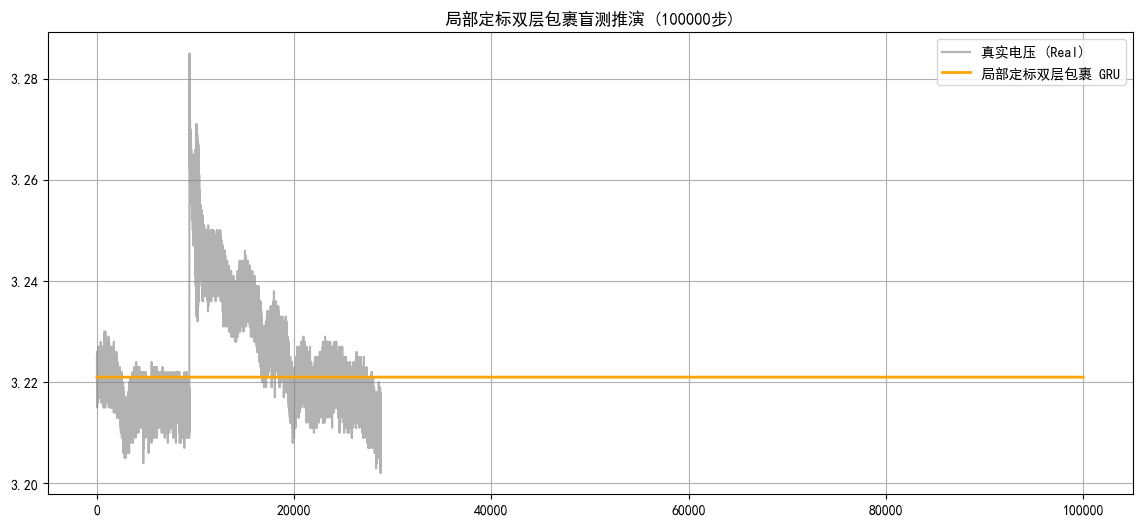

🔥 局部定标双层包裹盲测 (前 28770 步) 的 RMSE: 0.012038 V


In [4]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 核心 1：用“最后 2000 步”定标局部斜率 =================
t_train_real = df['Time (h)'].values[:split_idx]
v_train_real = df['Utot (V)'].values[:split_idx]

# 取最后 2000 步算平均斜率
local_v = v_train_real[-2000:]
local_t = t_train_real[-2000:]
# 真实局部的衰减率 (V/h)
local_slope = (local_v[0] - local_v[-1]) / (local_t[-1] - local_t[0])
print(f"🔍 920h 局部真实斜率：{local_slope:.6f} V/h")

# 顺便求一下局部斜率随时间的指数衰减系数（用于控制变缓速度）
# 我们用一个极小的衰减系数，比如 0.9998（每步缩小）
decay_rate = 0.9998

# ================= 核心 2：外推与双层包裹 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 100000 # 跑 10 万步
    predicted_voltages = []
    current_input = seed

    # 真实时间步长
    time_diff = t_train_real[1] - t_train_real[0]
    current_time = t_train_real[-1]

    last_temp_real = df['ToutH2 (°C)'].values[split_idx-1]
    last_hum_real = df['HrAIRFC (%)'].values[split_idx-1]

    last_v = current_input[:, -1, 1].item()
    # 反归一化当前的电压起点
    dummy = np.zeros((1, 4))
    dummy[0, 1] = last_v
    real_start_v = scaler.inverse_transform(dummy)[0, 1]

    print(f"开始双层包裹推演 {steps_to_predict} 步...")

    for step in range(steps_to_predict):
        # 1. AI 预测
        pred_y_scaled = model(current_input).item()
        dummy_p = np.zeros((1, 4))
        dummy_p[0, 1] = pred_y_scaled
        pred_real = scaler.inverse_transform(dummy_p)[0, 1]

        # 2. 计算物理下界（强制下滑的底线）
        current_time += time_diff
        # 随着时间推移，下滑速度呈指数衰减
        current_slope = local_slope * (decay_rate ** step)
        # 允许的单步最大跌幅 (注意 time_diff 是小时)
        step_drop = current_slope * time_diff

        # 下界：比上一步低 step_drop
        lower_bound = predicted_voltages[-1] - step_drop if step > 0 else real_start_v - step_drop
        # 上界：不能高于上一步
        upper_bound = predicted_voltages[-1] if step > 0 else real_start_v

        # 3. 融合：让 AI 预测值在 [下界, 上界] 之间！
        # 如果 AI 预测值跌穿了底线，就拉回底线
        if pred_real < lower_bound:
            fused_real = lower_bound
        # 如果 AI 预测值想反弹，就压平
        elif pred_real > upper_bound:
            fused_real = upper_bound
        else:
            fused_real = pred_real

        predicted_voltages.append(fused_real)

        # 4. 组装下一步输入
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        dummy_next[0, 1] = fused_real
        dummy_next[0, 2] = last_temp_real
        dummy_next[0, 3] = last_hum_real

        scaled_next = scaler.transform(dummy_next)
        next_time_scaled = min(scaled_next[0, 0], 1.2) # 防爆雷
        next_v_scaled = scaled_next[0, 1]

        next_step = torch.FloatTensor([[[next_time_scaled, next_v_scaled, last_temp_real, last_hum_real]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 画图 =================
true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predicted_voltages)), predicted_voltages, label='局部定标双层包裹 GRU', color='orange', linewidth=2)
plt.title(f'局部定标双层包裹盲测推演 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predicted_voltages), len(true_future))
if min_len > 0:
    rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predicted_voltages[:min_len]))
    print(f"🔥 局部定标双层包裹盲测 (前 {min_len} 步) 的 RMSE: {rmse_blind:.6f} V")

🔍 历史宏观平滑斜率: 0.000537 V/h
开始平滑宏观定标推演 100000 步...


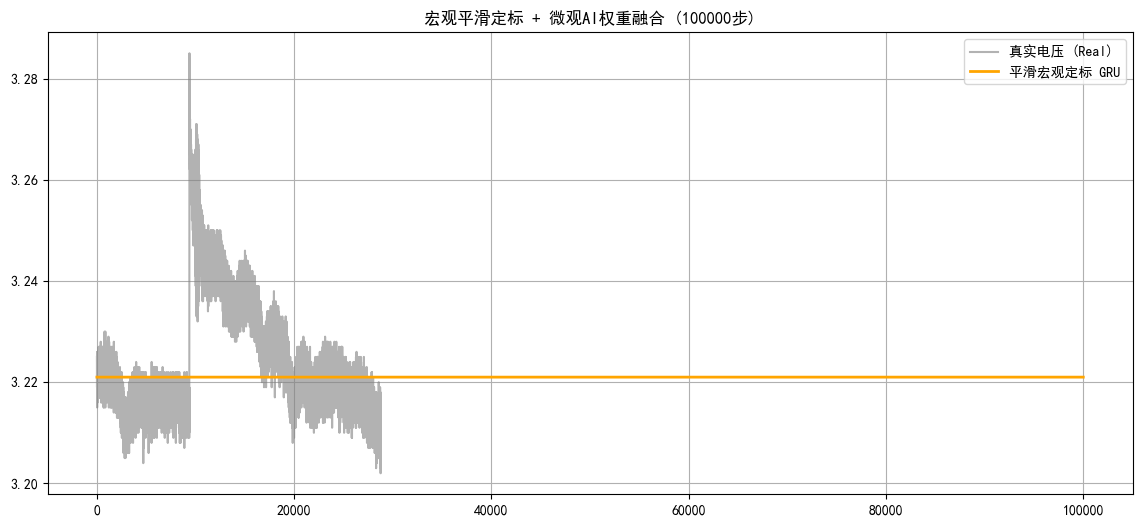

🔥 盲测 (前 28770 步) 的 RMSE: 0.012038 V


In [6]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 核心 1：宏观窗口定标（杜绝局部毛刺干扰） =================
t_train_real = df['Time (h)'].values[:split_idx]
v_train_real = df['Utot (V)'].values[:split_idx]

# 取最后 2000 个点（约 14 小时）算总降幅，求出整体平均斜率
window_len = 2000
v_end = v_train_real[-1]
v_start = v_train_real[-window_len]
t_end = t_train_real[-1]
t_start = t_train_real[-window_len]

# 这样算出来的斜率绝对是平滑的负数
real_slope = (v_end - v_start) / (t_end - t_start)
print(f"🔍 历史宏观平滑斜率: {real_slope:.6f} V/h")

# 设定斜率衰减率（指数衰减，代表二阶导为负且越来越趋近于 0）
slope_decay = 0.99998

# ================= 核心 2：权重融合推演 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 100000
    predicted_voltages = []
    current_input = seed

    time_diff = t_train_real[1] - t_train_real[0]
    current_time = t_train_real[-1]
    last_temp_real = df['ToutH2 (°C)'].values[split_idx-1]
    last_hum_real = df['HrAIRFC (%)'].values[split_idx-1]

    # 保证起始点从真实最后一点出发
    dummy = np.zeros((1, 4))
    dummy[0, 1] = current_input[:, -1, 1].item()
    real_start_v = scaler.inverse_transform(dummy)[0, 1]
    predicted_voltages.append(real_start_v)

    current_slope = real_slope

    print(f"开始平滑宏观定标推演 {steps_to_predict} 步...")

    for step in range(steps_to_predict):
        pred_y_scaled = model(current_input).item()
        dummy_p = np.zeros((1, 4))
        dummy_p[0, 1] = pred_y_scaled
        pred_real = scaler.inverse_transform(dummy_p)[0, 1]

        # 斜率随步数呈指数衰减（实现了二阶导限制且过渡平滑）
        current_slope = current_slope * slope_decay
        step_drop_physics = abs(current_slope) * time_diff

        # 物理骨架理论值
        v_physics = predicted_voltages[-1] - step_drop_physics

        # 【核心综合】0.85 权重给物理宏观骨架，0.15 留给 AI 微观波动
        fused_real = 0.85 * v_physics + 0.15 * pred_real

        # 【保险 1】不许反弹
        if fused_real > predicted_voltages[-1]:
            fused_real = predicted_voltages[-1]

        # 【保险 2】不许跌破物理下界（防止AI突然断崖）
        if fused_real < v_physics - step_drop_physics * 0.5:
            fused_real = v_physics - step_drop_physics * 0.5

        predicted_voltages.append(fused_real)

        # 时间推导
        current_time += time_diff
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        dummy_next[0, 1] = fused_real
        dummy_next[0, 2] = last_temp_real
        dummy_next[0, 3] = last_hum_real

        scaled_next = scaler.transform(dummy_next)
        next_time_scaled = min(scaled_next[0, 0], 1.2)
        next_v_scaled = scaled_next[0, 1]

        next_step = torch.FloatTensor([[[next_time_scaled, next_v_scaled, last_temp_real, last_hum_real]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 画图 =================
true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predicted_voltages)), predicted_voltages, label='平滑宏观定标 GRU', color='orange', linewidth=2)
plt.title(f'宏观平滑定标 + 微观AI权重融合 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predicted_voltages), len(true_future))
if min_len > 0:
    rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predicted_voltages[:min_len]))
    print(f"🔥 盲测 (前 {min_len} 步) 的 RMSE: {rmse_blind:.6f} V")

🔍 真实物理拟合结果：a=0.2694, b=0.000703, c=3.0787
✅ 拟合验证成功：理论渐近线电压为 3.0787 V，永远不可能跌穿。
开始指数全局定标推演 100000 步...


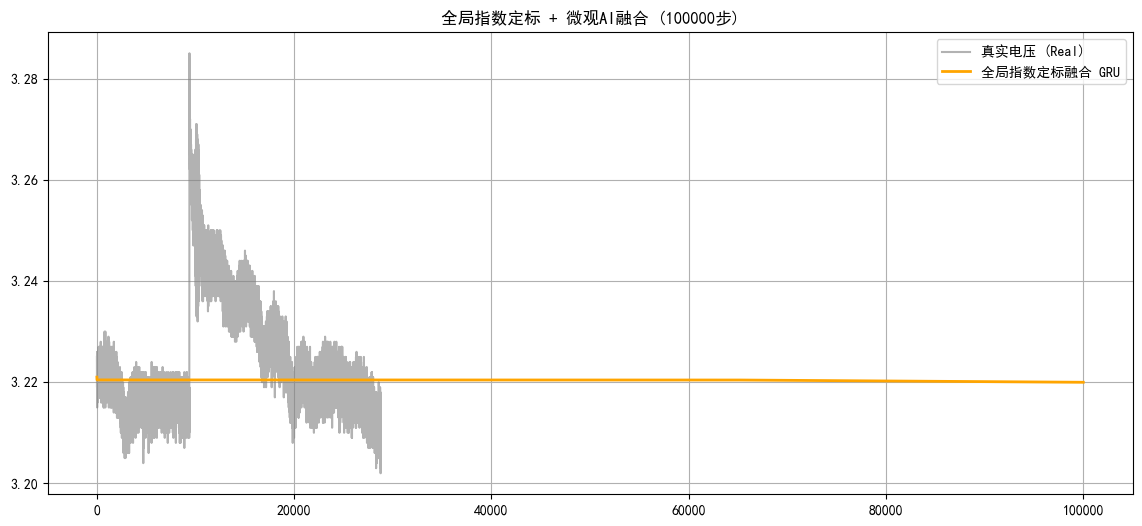

🔥 全局指数定标盲测 (前 28770 步) 的 RMSE: 0.012219 V


In [7]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error
from scipy.optimize import curve_fit

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 核心 1：用全局指数拟合来定标（绝对不会是正数） =================
t_train_real = df['Time (h)'].values[:split_idx]
v_train_real = df['Utot (V)'].values[:split_idx]

def exp_func(t, a, b, c):
    return a * np.exp(-b * t) + c

# 强制拟合出的 b 必须大于 0（强制衰减）
# 这里的 p0 给一个合理的猜测：初始差值 0.1，衰减率 0.001，渐近线 3.1
popt, _ = curve_fit(exp_func, t_train_real, v_train_real, p0=[0.1, 0.001, 3.1], maxfev=10000)
a_fit, b_fit, c_fit = popt

print(f"🔍 真实物理拟合结果：a={a_fit:.4f}, b={b_fit:.6f}, c={c_fit:.4f}")
if b_fit <= 0:
    print("⚠️ 警告：拟合出的衰减率 b 为负！")
else:
    print(f"✅ 拟合验证成功：理论渐近线电压为 {c_fit:.4f} V，永远不可能跌穿。")

# ================= 核心 2：推演与双层约束 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 100000
    predicted_voltages = []
    current_input = seed

    time_diff = t_train_real[1] - t_train_real[0]
    current_time = t_train_real[-1] # 起点时间 920h

    last_temp_real = df['ToutH2 (°C)'].values[split_idx-1]
    last_hum_real = df['HrAIRFC (%)'].values[split_idx-1]

    # 用真实的终点电压作为起点
    dummy = np.zeros((1, 4))
    dummy[0, 1] = current_input[:, -1, 1].item()
    real_start_v = scaler.inverse_transform(dummy)[0, 1]
    predicted_voltages.append(real_start_v)

    print(f"开始指数全局定标推演 {steps_to_predict} 步...")

    for step in range(steps_to_predict):
        # 1. AI 预测
        pred_y_scaled = model(current_input).item()
        dummy_p = np.zeros((1, 4))
        dummy_p[0, 1] = pred_y_scaled
        pred_real = scaler.inverse_transform(dummy_p)[0, 1]

        # 2. 计算时间推进和理论物理值
        current_time += time_diff
        v_theory_real = exp_func(current_time, *popt)

        # 3. 融合：80% 物理 + 20% AI
        fused_real = 0.8 * v_theory_real + 0.2 * pred_real

        # 4. 【物理绝对保险】不许上升
        if fused_real > predicted_voltages[-1]:
            fused_real = predicted_voltages[-1]

        predicted_voltages.append(fused_real)

        # 5. 准备下一步输入（归一化）
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        dummy_next[0, 1] = fused_real
        dummy_next[0, 2] = last_temp_real
        dummy_next[0, 3] = last_hum_real

        scaled_next = scaler.transform(dummy_next)
        next_time_scaled = scaled_next[0, 0]
        next_v_scaled = scaled_next[0, 1]

        # 防爆雷：限制时间不超出网络认知范围（归一化后最大1.2）
        next_time_scaled = min(next_time_scaled, 1.2)

        next_step = torch.FloatTensor([[[next_time_scaled, next_v_scaled, last_temp_real, last_hum_real]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 画图 =================
true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predicted_voltages)), predicted_voltages, label='全局指数定标融合 GRU', color='orange', linewidth=2)
plt.title(f'全局指数定标 + 微观AI融合 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predicted_voltages), len(true_future))
if min_len > 0:
    rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predicted_voltages[:min_len]))
    print(f"🔥 全局指数定标盲测 (前 {min_len} 步) 的 RMSE: {rmse_blind:.6f} V")

🔍 真实物理拟合结果：a=0.2694, b=0.000703, c=3.0787
✅ 拟合验证成功：理论渐近线电压为 3.0787 V，永远不可能跌穿。
开始指数全局定标推演 100000 步...


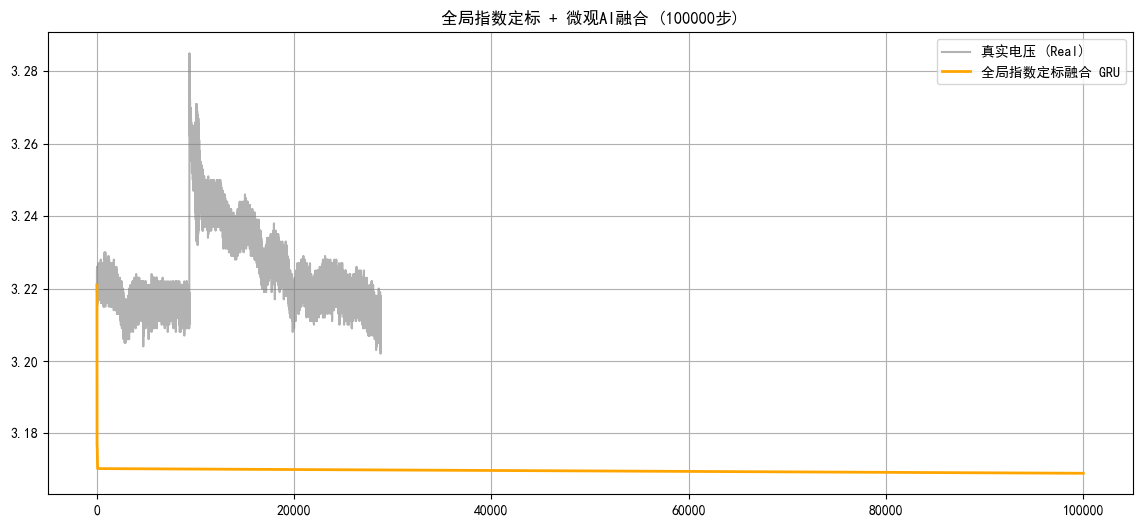

🔥 全局指数定标盲测 (前 28770 步) 的 RMSE: 0.055858 V


In [4]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import math
from sklearn.metrics import mean_squared_error
from scipy.optimize import curve_fit

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 核心 1：用全局指数拟合来定标（绝对不会是正数） =================
t_train_real = df['Time (h)'].values[:split_idx]
v_train_real = df['Utot (V)'].values[:split_idx]

def exp_func(t, a, b, c):
    return a * np.exp(-b * t) + c

# 强制拟合出的 b 必须大于 0（强制衰减）
# 这里的 p0 给一个合理的猜测：初始差值 0.1，衰减率 0.001，渐近线 3.1
popt, _ = curve_fit(exp_func, t_train_real, v_train_real, p0=[0.1, 0.001, 3.1], maxfev=10000)
a_fit, b_fit, c_fit = popt

print(f"🔍 真实物理拟合结果：a={a_fit:.4f}, b={b_fit:.6f}, c={c_fit:.4f}")
if b_fit <= 0:
    print("⚠️ 警告：拟合出的衰减率 b 为负！")
else:
    print(f"✅ 拟合验证成功：理论渐近线电压为 {c_fit:.4f} V，永远不可能跌穿。")

# ================= 核心 2：推演与双层约束 =================
model.eval()
with torch.no_grad():
    seed = torch.FloatTensor(train_scaled[-SEQ_LENGTH:]).unsqueeze(0)
    steps_to_predict = 100000
    predicted_voltages = []
    current_input = seed

    time_diff = t_train_real[1] - t_train_real[0]
    current_time = t_train_real[-1] # 起点时间 920h

    last_temp_real = df['ToutH2 (°C)'].values[split_idx-1]
    last_hum_real = df['HrAIRFC (%)'].values[split_idx-1]

    # 用真实的终点电压作为起点
    dummy = np.zeros((1, 4))
    dummy[0, 1] = current_input[:, -1, 1].item()
    real_start_v = scaler.inverse_transform(dummy)[0, 1]
    predicted_voltages.append(real_start_v)

    print(f"开始指数全局定标推演 {steps_to_predict} 步...")

    for step in range(steps_to_predict):
        # 1. AI 预测
        pred_y_scaled = model(current_input).item()
        dummy_p = np.zeros((1, 4))
        dummy_p[0, 1] = pred_y_scaled
        pred_real = scaler.inverse_transform(dummy_p)[0, 1]

        # 2. 计算时间推进和理论物理值
        current_time += time_diff
        v_theory_real = exp_func(current_time, *popt)

        # 3. 融合：80% 物理 + 20% AI
        fused_real = 0.8 * v_theory_real + 0.2 * pred_real

        # 4. 【物理绝对保险】不许上升
        if fused_real > predicted_voltages[-1]:
            fused_real = predicted_voltages[-1]

        predicted_voltages.append(fused_real)

        # 5. 准备下一步输入（归一化）
        dummy_next = np.zeros((1, 4))
        dummy_next[0, 0] = current_time
        dummy_next[0, 1] = fused_real
        dummy_next[0, 2] = last_temp_real
        dummy_next[0, 3] = last_hum_real

        scaled_next = scaler.transform(dummy_next)
        next_time_scaled = scaled_next[0, 0]
        next_v_scaled = scaled_next[0, 1]

        # 防爆雷：限制时间不超出网络认知范围（归一化后最大1.2）
        next_time_scaled = min(next_time_scaled, 1.2)

        next_step = torch.FloatTensor([[[next_time_scaled, next_v_scaled, last_temp_real, last_hum_real]]])
        current_input = torch.cat((current_input[:, 1:, :], next_step), dim=1)

# ================= 画图 =================
true_future = df['Utot (V)'].values[split_idx : split_idx + steps_to_predict]

plt.figure(figsize=(14, 6))
plt.plot(range(len(true_future)), true_future, label='真实电压 (Real)', color='gray', alpha=0.6)
plt.plot(range(len(predicted_voltages)), predicted_voltages, label='全局指数定标融合 GRU', color='orange', linewidth=2)
plt.title(f'全局指数定标 + 微观AI融合 ({steps_to_predict}步)')
plt.legend()
plt.grid(True)
plt.show()

min_len = min(len(predicted_voltages), len(true_future))
if min_len > 0:
    rmse_blind = math.sqrt(mean_squared_error(true_future[:min_len], predicted_voltages[:min_len]))
    print(f"🔥 全局指数定标盲测 (前 {min_len} 步) 的 RMSE: {rmse_blind:.6f} V")